# Prédiction des frais médicaux d'assurance santé

**Auteur :** Ahmadou Moukhtar — Master professionnel en ingénierie de l'IA

---

## Contexte

Une compagnie d'assurance santé veut estimer, à partir du profil d'un assuré, les **frais médicaux** qu'il va lui coûter.
Une bonne estimation sert à fixer des primes justes, à anticiper les dépenses et à repérer les profils à risque.

## Objectif

Construire un modèle de **régression** qui prédit la variable `charges` (frais médicaux facturés, en dollars) et qui soit :

- **précis** : erreur de prédiction la plus faible possible ;
- **interprétable** : on doit pouvoir expliquer quels facteurs font augmenter les frais ;
- **fiable** : hypothèses vérifiées et choix du modèle fait sans tricher avec le jeu de test.

## Données

Jeu de données public *Medical Cost Personal Dataset* (Kaggle) : 1 338 assurés, 7 colonnes, aucune valeur manquante.

| Colonne d'origine | Nom dans le notebook | Description |
|---|---|---|
| `age` | `age` | Âge de l'assuré (18 à 64 ans) |
| `sex` | `sexe` | Sexe |
| `bmi` | `imc` | Indice de masse corporelle (kg/m²) |
| `children` | `enfants` | Nombre d'enfants couverts par l'assurance |
| `smoker` | `fumeur` | Fumeur ou non |
| `region` | `region` | Région de résidence aux États-Unis |
| `charges` | `charges_assurance` | **Cible** : frais médicaux facturés par l'assurance (et non une prime) |

## Plan du notebook

1. **Analyse exploratoire (EDA)** : qualité des données, distributions, liens avec la cible
2. **Prétraitement** : encodage, séparation train/test, standardisation, sélection des variables
3. **Régression linéaire** : modèle de référence
4. **Vérification des hypothèses** : linéarité, homoscédasticité, normalité, multicolinéarité, points influents
5. **Autres modèles linéaires** : Huber, polynomial, GLM Gamma
6. **Modèles non linéaires** : arbre, Random Forest, Gradient Boosting, XGBoost, LightGBM, SVR, k-NN
7. **Comparaison des modèles** par validation croisée
8. **Modèle final et conclusion**

> **Règles suivies dans tout le projet :**
> - le jeu de test n'est jamais utilisé pour faire un choix (variables, hyperparamètres, modèle) : il sert uniquement à mesurer la performance finale ;
> - les modèles n'utilisent **que les variables fournies par l'entreprise** : aucune variable n'est créée à la main.

---
# **Importation des bibliothèques**

In [1]:
import os
import warnings
%pip install joblib xgboost lightgbm
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Prétraitement
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

# Modèles linéaires
from sklearn.linear_model import LinearRegression, HuberRegressor, GammaRegressor

# Modèles non linéaires
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Évaluation et validation
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_gamma_deviance

# Vérification des hypothèses (statistiques)
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow, normal_ad
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Réglages d'affichage
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
# Graine aléatoire unique : les résultats sont reproductibles d'une exécution à l'autre
GRAINE = 42

Note: you may need to restart the kernel to use updated packages.


---
# **Étape 1 — Analyse exploratoire des données (EDA)**

**But :** comprendre les données avant de modéliser : leur qualité (valeurs manquantes, doublons),
la forme des distributions et les variables qui semblent influencer les frais médicaux.

## **1.1 Chargement et informations générales**

In [3]:
df = pd.read_csv("insurance.csv")
print("Fichier chargé :", chemin)
df.head()

Fichier chargé : C:/Users/Administrateur/Downloads/assurance/insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Renommage des colonnes en français (age et region gardent leur nom)
df = df.rename(columns={
    "sex": "sexe",
    "bmi": "imc",
    "children": "enfants",
    "smoker": "fumeur",
    "charges": "charges_assurance",
})

In [5]:
# Traduction des modalités des variables catégorielles
df["sexe"] = df["sexe"].replace({"male": "Homme", "female": "Femme"})
df["fumeur"] = df["fumeur"].replace({"yes": "Oui", "no": "Non"})
df["region"] = df["region"].replace({
    "northeast": "Nord-Est",
    "northwest": "Nord-Ouest",
    "southeast": "Sud-Est",
    "southwest": "Sud-Ouest",
})

df.head()

,age,sexe,imc,enfants,fumeur,region,charges_assurance
0,19,Femme,27.900,0,Oui,Sud-Ouest,16884.92400
1,18,Homme,33.770,1,Non,Sud-Est,1725.55230
2,28,Homme,33.000,3,Non,Sud-Est,4449.46200
3,33,Homme,22.705,0,Non,Nord-Ouest,21984.47061
4,32,Homme,28.880,0,Non,Nord-Ouest,3866.85520


In [6]:
# Types des colonnes, nombre de valeurs non nulles et mémoire utilisée
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1338 non-null   int64  
 1   sexe               1338 non-null   object 
 2   imc                1338 non-null   float64
 3   enfants            1338 non-null   int64  
 4   fumeur             1338 non-null   object 
 5   region             1338 non-null   object 
 6   charges_assurance  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Le jeu contient **1 338 lignes et 7 colonnes** : 3 variables numériques explicatives (`age`, `imc`, `enfants`),
3 variables catégorielles (`sexe`, `fumeur`, `region`) et la cible numérique `charges_assurance`.

## **1.2 Analyse des valeurs manquantes**

In [7]:
# Nombre de valeurs manquantes par colonne
df.isnull().sum()

age                  0
sexe                 0
imc                  0
enfants              0
fumeur               0
region               0
charges_assurance    0
dtype: int64

Aucune valeur manquante : pas d'imputation nécessaire.

## **1.3 Vérification et suppression des lignes en double**

In [8]:
# Compter les lignes entièrement identiques
print("Nombre de doublons :", df.duplicated().sum())

# Afficher toutes les lignes concernées (keep=False garde l'original et sa copie)
df[df.duplicated(keep=False)]

Nombre de doublons : 1


,age,sexe,imc,enfants,fumeur,region,charges_assurance
195,19,Homme,30.59,0,Non,Nord-Ouest,1639.5631
581,19,Homme,30.59,0,Non,Nord-Ouest,1639.5631


In [9]:
# Supprimer les doublons en gardant la première occurrence, puis renuméroter les lignes
df = df.drop_duplicates(keep="first").reset_index(drop=True)

# Vérification
print("Doublons restants :", df.duplicated().sum())
print("Dimensions :", df.shape)

Doublons restants : 0
Dimensions : (1337, 7)


Une ligne en double (même âge, sexe, IMC, région et mêmes charges) a été supprimée :
il reste **1 337 assurés**. Garder un doublon reviendrait à donner deux fois plus de poids à cette personne,
et il pourrait se retrouver à la fois dans le train et dans le test.

## **1.4 Statistiques descriptives**

In [10]:
# Variables numériques : moyenne, écart-type, minimum, quartiles, maximum
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.22,14.04,18.00,27.00,39.00,51.00,64.00
imc,1337.0,30.66,6.10,15.96,26.29,30.40,34.70,53.13
enfants,1337.0,1.10,1.21,0.00,0.00,1.00,2.00,5.00
charges_assurance,1337.0,13279.12,12110.36,1121.87,4746.34,9386.16,16657.72,63770.43


In [11]:
# Variables catégorielles : nombre de modalités, modalité la plus fréquente et sa fréquence
df.describe(exclude="number").T

,count,unique,top,freq
sexe,1337,2,Homme,675
fumeur,1337,2,Non,1063
region,1337,4,Sud-Est,364


**Lecture :**

- Les assurés ont entre 18 et 64 ans ; l'IMC moyen (30,7) est à la limite de l'obésité (IMC ≥ 30 selon l'OMS).
- Les charges vont d'environ 1 100 à 63 800 dollars. La moyenne (13 279) est bien au-dessus de la médiane (9 386) :
  quelques assurés ont des frais très élevés, la distribution est **asymétrique à droite**.
- Seulement **20 % de fumeurs** (274 sur 1 337). Hommes et femmes sont en proportion égale, les 4 régions aussi.

## **1.5 Distribution des variables**

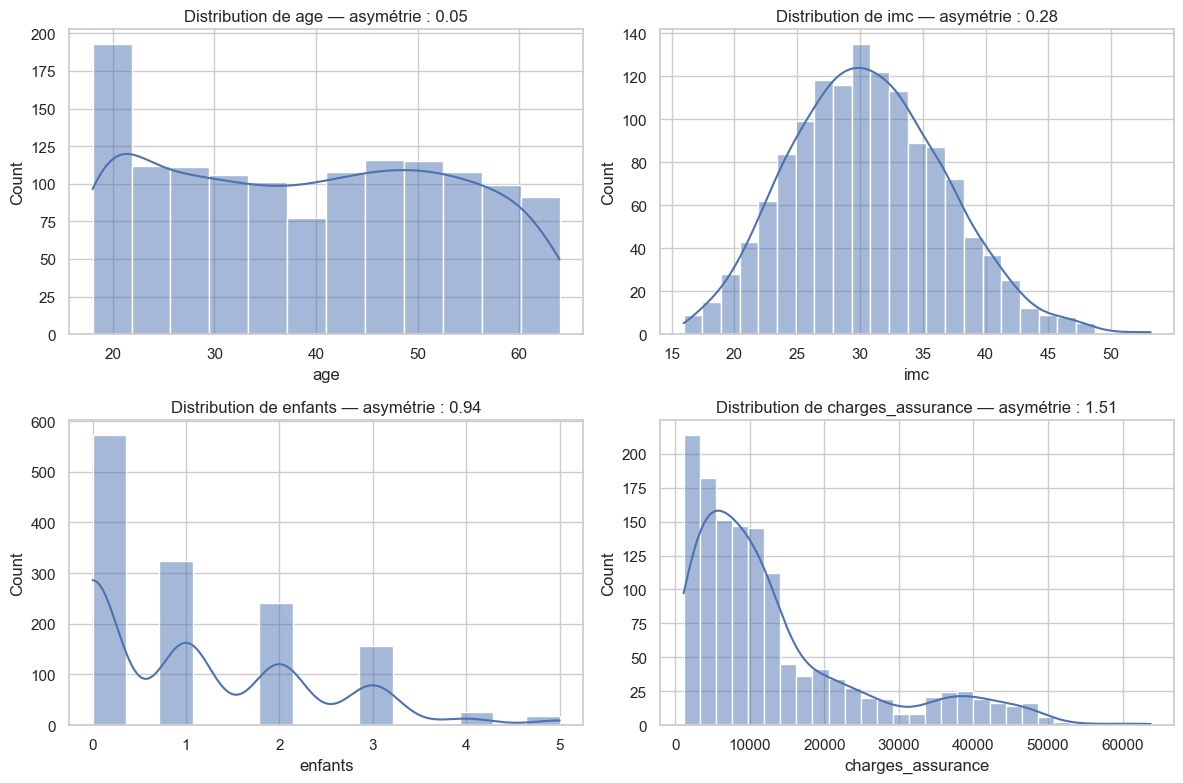

In [12]:
# Sélectionner uniquement les colonnes numériques
colonnes_numeriques = df.select_dtypes("number")

# Créer une grille de graphiques à 2 colonnes
n_col = 2
n_lig = (len(colonnes_numeriques.columns) + n_col - 1) // n_col
fig, axs = plt.subplots(n_lig, n_col, figsize=(6 * n_col, 4 * n_lig))

# Transformer la grille en tableau à une dimension pour la parcourir simplement
axs = axs.ravel()

for i, colonne in enumerate(colonnes_numeriques):
    # Histogramme + courbe de densité (KDE)
    sns.histplot(data=colonnes_numeriques, x=colonne, kde=True, ax=axs[i])

    # Asymétrie : 0 = symétrique, > 0 = queue à droite, < 0 = queue à gauche
    asymetrie = stats.skew(df[colonne])
    axs[i].set_title(f"Distribution de {colonne} — asymétrie : {asymetrie:.2f}")

# Masquer les emplacements inutilisés de la grille
for j in range(len(colonnes_numeriques.columns), len(axs)):
    axs[j].set_visible(False)

plt.tight_layout()
plt.show()

**Lecture :**

- `age` est presque uniforme (asymétrie 0,05), avec un pic à 18-19 ans.
- `imc` suit une loi proche de la loi normale (asymétrie 0,28).
- `enfants` est discrète : la plupart des assurés ont 0 à 2 enfants.
- `charges_assurance` est **fortement asymétrique (1,51)** : beaucoup de frais faibles, peu de frais très élevés.
  Cette forme justifiera de tester, à l'étape 5, un modèle adapté aux cibles positives et asymétriques (GLM Gamma).

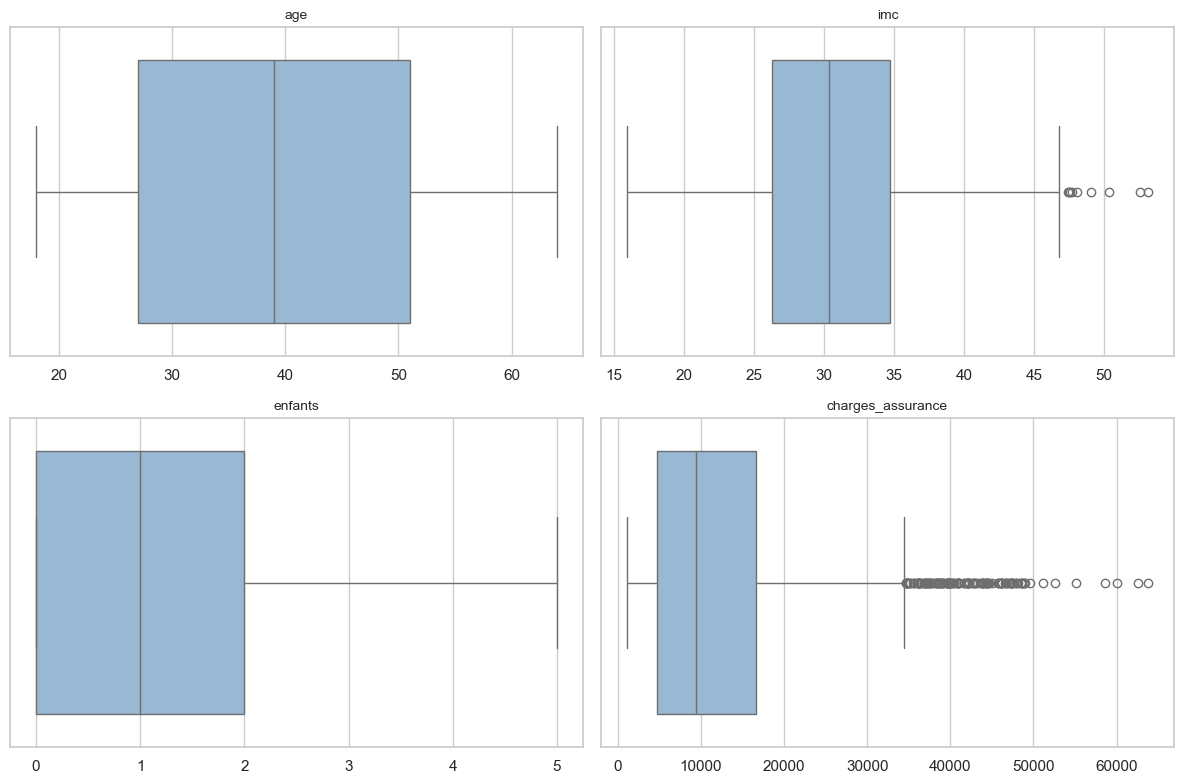

In [13]:
# Boîtes à moustaches : repérer les valeurs extrêmes (points au-delà des moustaches)
cols = list(colonnes_numeriques.columns)
ncol = 2
nrow = (len(cols) + ncol - 1) // ncol

fig, axs = plt.subplots(nrow, ncol, figsize=(6 * ncol, 4 * nrow))
for ax, c in zip(axs.ravel(), cols):
    sns.boxplot(x=df[c], ax=ax, color="#8FB8DE")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

**Lecture :** `charges_assurance` présente environ 140 valeurs au-dessus de la moustache haute et `imc` une dizaine.
Ce ne sont pas des erreurs de saisie : ce sont des assurés réels aux frais élevés (on verra qu'il s'agit surtout de fumeurs).
**On les conserve** ; leur influence sur le modèle sera contrôlée à l'étape 4.4 (distance de Cook).

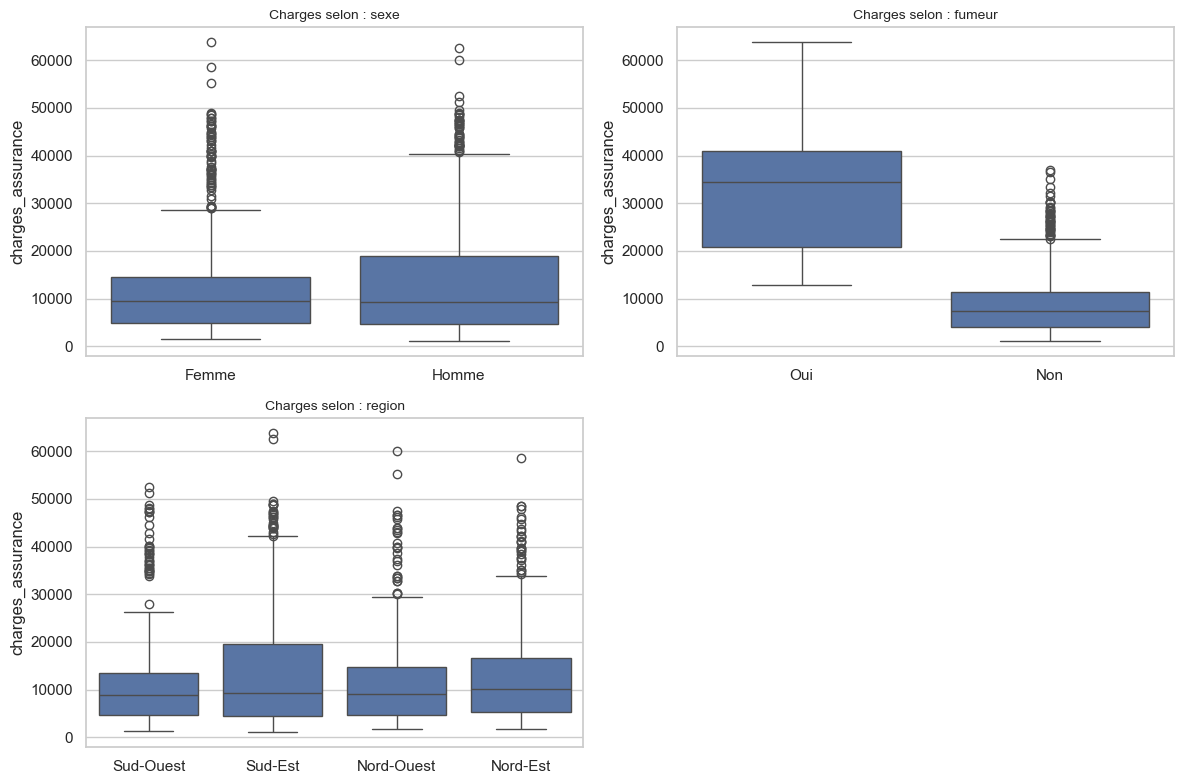

In [14]:
# Charges selon chaque variable catégorielle
cols_cat = list(df.select_dtypes(exclude="number").columns)
ncol_cat = 2
nrow_cat = (len(cols_cat) + ncol_cat - 1) // ncol_cat

fig, axs_cat = plt.subplots(nrow_cat, ncol_cat, figsize=(6 * ncol_cat, 4 * nrow_cat))
for ax, c in zip(axs_cat.ravel(), cols_cat):
    sns.boxplot(data=df, x=c, y="charges_assurance", ax=ax)
    ax.set_title(f"Charges selon : {c}", fontsize=10)
    ax.set_xlabel("")

# Masquer les axes vides
for ax in axs_cat.ravel()[len(cols_cat):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
# Chiffres derrière le graphique : charges médianes et moyennes selon le tabagisme
df.groupby("fumeur")["charges_assurance"].agg(["count", "median", "mean"]).round(0)

,count,median,mean
fumeur,,,
Non,1063,7346.0,8441.0
Oui,274,34456.0,32050.0


**Lecture :** le **tabagisme** est de loin le facteur le plus marquant : la charge médiane d'un fumeur
(environ 34 500) est **plus de 4 fois** celle d'un non-fumeur (environ 7 300).
Le sexe et la région ne montrent que de faibles différences de médiane.

## **1.6 Corrélation entre les variables**

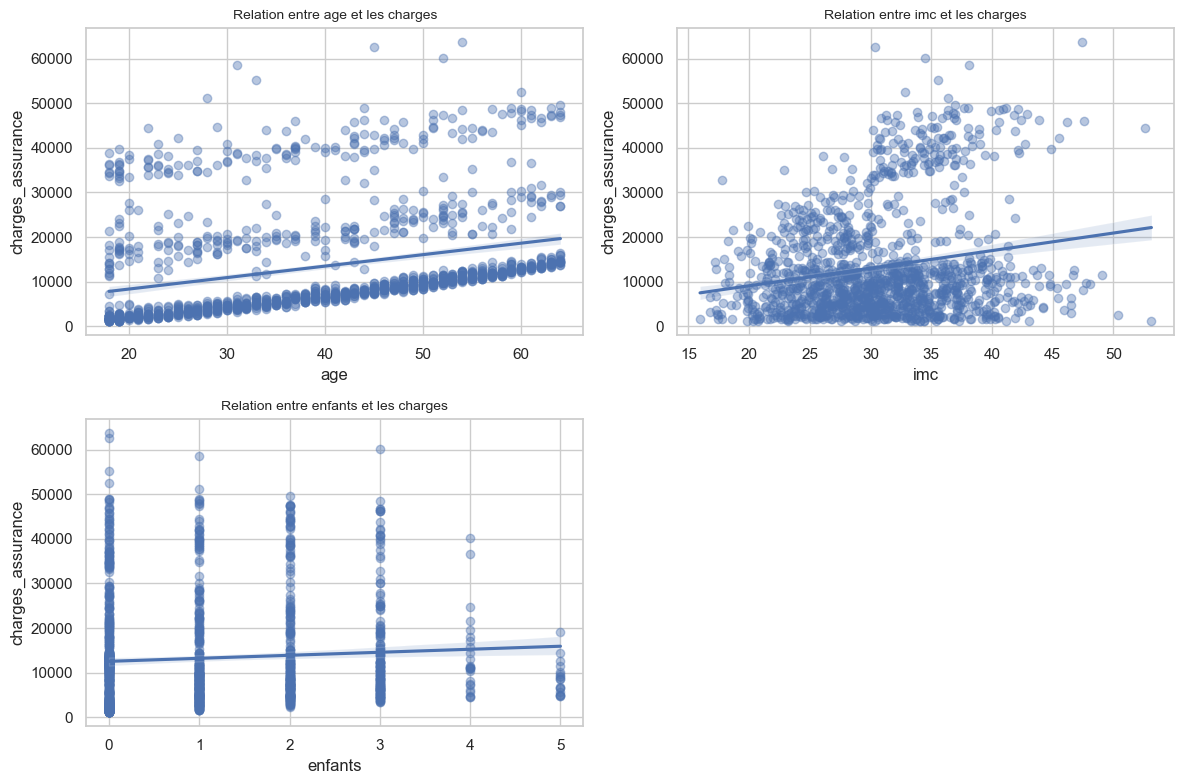

In [16]:
# Relation entre chaque variable numérique et la cible (nuage de points + droite de régression)
cols_to_plot = df.select_dtypes("number").columns.drop("charges_assurance")
n_col = 2
n_ligne = (len(cols_to_plot) + n_col - 1) // n_col

fig, axs = plt.subplots(n_ligne, n_col, figsize=(6 * n_col, 4 * n_ligne))
for ax, c in zip(axs.ravel(), cols_to_plot):
    sns.regplot(data=df, x=c, y="charges_assurance", ax=ax, scatter_kws={"alpha": 0.4})
    ax.set_title(f"Relation entre {c} et les charges", fontsize=10)

# Masquer les axes vides
for ax in axs.ravel()[len(cols_to_plot):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Lecture :** les charges augmentent avec l'âge, en formant **trois bandes** parallèles. Ces bandes suggèrent
qu'un autre facteur (le tabac, et l'IMC chez les fumeurs) sépare les assurés en groupes de niveaux de frais différents.

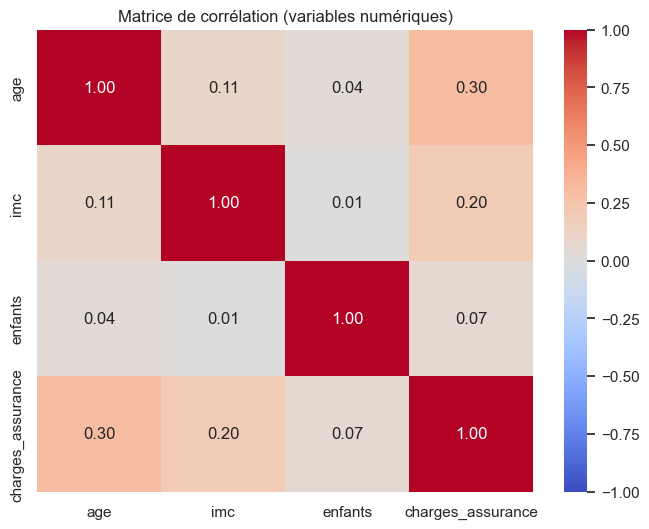

In [17]:
# Matrice de corrélation de Pearson entre variables numériques
matrice = df.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation (variables numériques)")
plt.show()

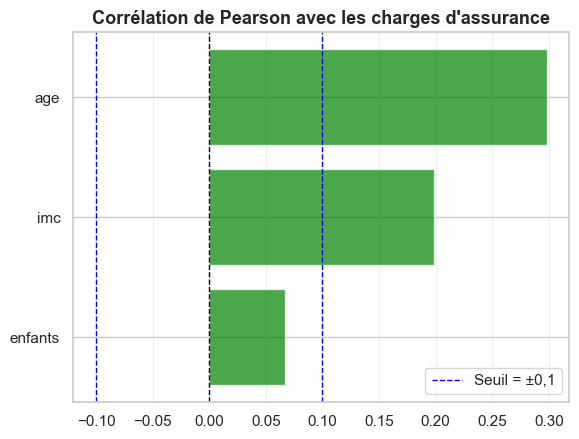

In [18]:
# Corrélation de chaque variable numérique avec la cible, triée par valeur absolue
corr_cible = matrice["charges_assurance"].drop("charges_assurance")
corr_cible = corr_cible.reindex(corr_cible.abs().sort_values().index)

couleurs = ["green" if x > 0 else "red" for x in corr_cible]
plt.barh(corr_cible.index, corr_cible.values, color=couleurs, alpha=0.7)
plt.grid(alpha=0.3, axis="x")
plt.axvline(x=0, color="black", linestyle="--", linewidth=1)
plt.axvline(x=0.1, color="blue", linestyle="--", linewidth=1, label="Seuil = ±0,1")
plt.axvline(x=-0.1, color="blue", linestyle="--", linewidth=1)
plt.title("Corrélation de Pearson avec les charges d'assurance", fontsize=13, fontweight="bold")
plt.legend()
plt.show()

**Lecture :** les corrélations linéaires avec les charges sont modestes : `age` (0,30), `imc` (0,20) et `enfants` (0,07).
Les variables explicatives sont très peu corrélées entre elles (≤ 0,11) : pas de risque de multicolinéarité.

Attention : la corrélation de Pearson ne mesure qu'un lien **linéaire** et **global**.
Une variable peu corrélée en moyenne peut être très importante dans un sous-groupe : c'est ce qu'on vérifie ci-dessous pour l'IMC.

## **1.7 Relation entre l'IMC et les charges : fumeurs et non-fumeurs**

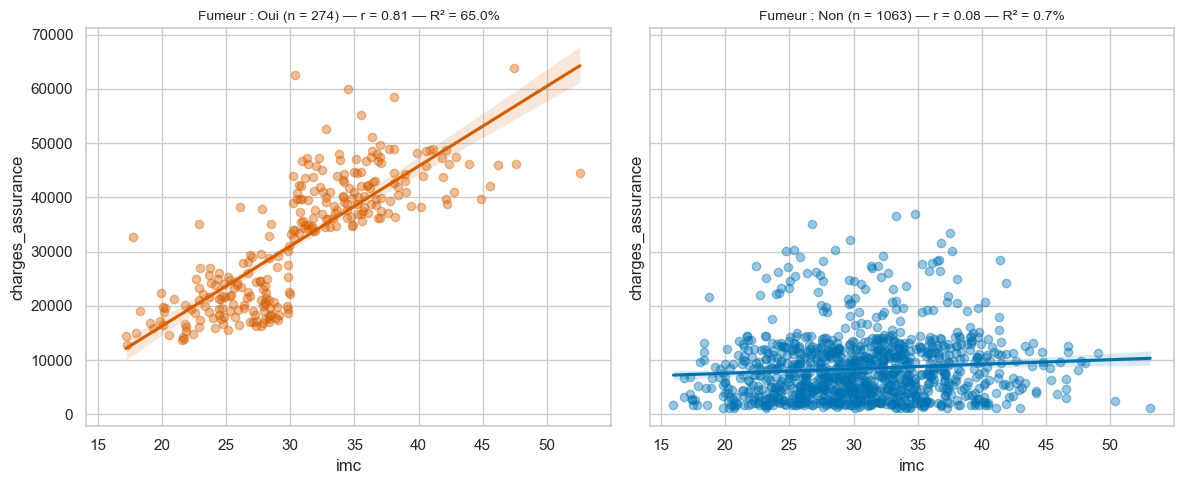

In [19]:
# Relation entre l'IMC et les charges, séparément pour les fumeurs et les non-fumeurs
couleurs_fumeur = {"Oui": "#D55E00", "Non": "#0072B2"}

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, modalite in zip(axs.ravel(), ["Oui", "Non"]):
    groupe = df[df["fumeur"] == modalite]
    r = groupe["imc"].corr(groupe["charges_assurance"])
    sns.regplot(data=groupe, x="imc", y="charges_assurance", ax=ax,
                color=couleurs_fumeur[modalite], scatter_kws={"alpha": 0.4})
    ax.set_title(f"Fumeur : {modalite} (n = {len(groupe)}) — r = {r:.2f} — R² = {r ** 2:.1%}", fontsize=10)

plt.tight_layout()
plt.show()

**Interprétation — un résultat clé du projet :**

- **Chez les fumeurs**, la corrélation entre l'IMC et les charges est très forte (r ≈ 0,81) :
  l'IMC explique à lui seul environ 65 % de la variabilité de leurs frais. On voit même un saut net autour de **IMC = 30** (obésité).
- **Chez les non-fumeurs**, l'IMC n'a presque aucun effet (r ≈ 0,08).

L'effet de l'IMC **dépend donc du tabagisme** : c'est une **interaction**. Les non-fumeurs étant 4 fois plus nombreux,
ils « diluent » cet effet dans la corrélation globale (0,20). Un modèle linéaire simple ne peut pas capter cette interaction
tout seul : on s'en souviendra aux étapes 4, 5 et 6.

---
# **Étape 2 — Prétraitement**

**But :** transformer les données dans un format exploitable par les modèles, sans **fuite de données**
(*data leakage*) : aucune information du jeu de test ne doit servir à préparer les données d'entraînement.

## **2.1 Encodage des variables catégorielles (One-Hot)**

Les modèles ne comprennent que des nombres. Chaque variable catégorielle est remplacée par des colonnes 0/1.
Avec `drop="first"`, on supprime une modalité de référence (par exemple `Femme`, `Non`, `Nord-Est`) pour éviter
une redondance parfaite entre colonnes (*piège des variables indicatrices*).

L'encodage est fait avant la séparation train/test : ce n'est pas une fuite, car il n'apprend
**que la liste des modalités**, sans aucune statistique sur les valeurs ni sur la cible.

In [20]:
# Colonnes catégorielles à encoder
colonnes_cat = df.select_dtypes(exclude="number").columns

# Créer et appliquer l'encodeur
encodeur = OneHotEncoder(drop="first", sparse_output=False)
resultat = encodeur.fit_transform(df[colonnes_cat])

# Remettre le résultat dans un DataFrame avec des noms de colonnes lisibles
df_ohe = pd.DataFrame(resultat, columns=encodeur.get_feature_names_out(colonnes_cat), index=df.index)
df_ohe.head()

,sexe_Homme,fumeur_Oui,region_Nord-Ouest,region_Sud-Est,region_Sud-Ouest
0,0.0,1.0,0.0,0.0,1.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0
3,1.0,0.0,1.0,0.0,0.0
4,1.0,0.0,1.0,0.0,0.0


## **2.2 Remplacer les variables catégorielles par les variables encodées**

In [21]:
df = pd.concat([df.drop(columns=colonnes_cat), df_ohe], axis=1)
df.head()

,age,imc,enfants,charges_assurance,sexe_Homme,fumeur_Oui,region_Nord-Ouest,region_Sud-Est,region_Sud-Ouest
0,19,27.900,0,16884.92400,0.0,1.0,0.0,0.0,1.0
1,18,33.770,1,1725.55230,1.0,0.0,0.0,1.0,0.0
2,28,33.000,3,4449.46200,1.0,0.0,0.0,1.0,0.0
3,33,22.705,0,21984.47061,1.0,0.0,1.0,0.0,0.0
4,32,28.880,0,3866.85520,1.0,0.0,1.0,0.0,0.0


## **2.3 Séparation entraînement / test**

- **Train (80 %)** : sert à entraîner les modèles et à faire tous les choix (variables, hyperparamètres, modèle).
- **Test (20 %)** : mis de côté, utilisé uniquement pour mesurer la performance finale sur des données jamais vues.

In [22]:
CIBLE = "charges_assurance"

# Variables explicatives (X) et cible (y), sélectionnées par leur nom (plus sûr qu'une position)
X = df.drop(columns=CIBLE)
y = df[CIBLE]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=GRAINE,
)

# Copies indépendantes : on peut les modifier sans toucher à X
X_train = X_train.copy()
X_test = X_test.copy()
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (1069, 8) | Test : (268, 8)


## **2.4 Standardisation des variables numériques**

La standardisation ramène chaque variable à une moyenne de 0 et un écart-type de 1 : `z = (x − moyenne) / écart-type`.
Elle est indispensable pour les modèles basés sur des distances (k-NN, SVR) et pour comparer les coefficients entre eux.

**Règle anti-fuite :** la moyenne et l'écart-type sont calculés **sur le train uniquement** (`fit_transform`),
puis appliqués tels quels au test (`transform`).

In [23]:
# Variables numériques à standardiser (pas les colonnes 0/1, ni la cible)
colonnes_num = ["age", "imc", "enfants"]

scaler = StandardScaler()

# Apprendre la moyenne et l'écart-type sur le train, puis transformer le train
X_train[colonnes_num] = scaler.fit_transform(X_train[colonnes_num])

# Appliquer exactement les mêmes paramètres au test
X_test[colonnes_num] = scaler.transform(X_test[colonnes_num])

# Paramètres appris, conservés pour revenir aux unités réelles plus tard
moyennes = dict(zip(colonnes_num, scaler.mean_))
ecarts_types = dict(zip(colonnes_num, scaler.scale_))
X_train.head()

,age,imc,enfants,sexe_Homme,fumeur_Oui,region_Nord-Ouest,region_Sud-Est,region_Sud-Ouest
1113,-1.157680,-0.996928,-0.907908,1.0,0.0,0.0,0.0,0.0
967,-1.300619,-0.792762,0.766904,1.0,0.0,0.0,0.0,0.0
598,0.914926,1.154664,0.766904,0.0,0.0,1.0,0.0,0.0
170,1.701087,1.806837,-0.907908,1.0,0.0,0.0,1.0,0.0
275,0.557580,-0.651417,0.766904,0.0,0.0,0.0,0.0,0.0


## **2.5 Sélection des variables numériques (seuil |ρ| ≥ 0,1)**

On écarte les variables numériques dont la corrélation avec la cible est inférieure à **0,1** en valeur absolue.
Cette sélection utilise la cible : elle est donc faite **sur le train uniquement**.
Les variables catégorielles (`sexe`, `fumeur`, `region`) sont toutes conservées.

In [24]:
SEUIL_CORR = 0.1

# Corrélation (en valeur absolue) de chaque variable numérique avec la cible, sur le train
corr_train = X_train[colonnes_num].corrwith(y_train, method="pearson").abs().sort_values(ascending=False)

variables_retenues = corr_train[corr_train >= SEUIL_CORR]
variables_ecartees = corr_train[corr_train < SEUIL_CORR]

print("Variables retenues :\n", variables_retenues.round(3), "\n")
print("Variables écartées :\n", variables_ecartees.round(3))

Variables retenues :
 age    0.290
imc    0.178
dtype: float64 

Variables écartées :
 enfants    0.086
dtype: float64


In [25]:
# Vérification : la variable enfants a-t-elle un effet caché dans un sous-groupe (comme l'IMC) ?
fumeur_train = X_train["fumeur_Oui"] == 1
for nom, masque in [("Fumeurs", fumeur_train), ("Non-fumeurs", ~fumeur_train)]:
    r = X_train.loc[masque, "enfants"].corr(y_train[masque])
    print(f"{nom:12s} : r = {r:.3f}  ->  R² = {r ** 2:.1%}")

Fumeurs      : r = 0.061  ->  R² = 0.4%
Non-fumeurs  : r = 0.146  ->  R² = 2.1%


**Décision :** `enfants` est écartée. Sa corrélation globale est très faible (0,09, soit 0,7 % de variabilité expliquée)
et, contrairement à l'IMC, elle ne cache pas d'effet fort dans un sous-groupe (au plus 2 % chez les non-fumeurs).

## **2.6 Retrait des variables écartées**

In [26]:
X_train = X_train.drop(columns=variables_ecartees.index)
X_test = X_test.drop(columns=variables_ecartees.index)
print("Variables utilisées par les modèles :", list(X_train.columns))
print("Train :", X_train.shape, "| Test :", X_test.shape)

Variables utilisées par les modèles : ['age', 'imc', 'sexe_Homme', 'fumeur_Oui', 'region_Nord-Ouest', 'region_Sud-Est', 'region_Sud-Ouest']
Train : (1069, 7) | Test : (268, 7)


---
# **Étape 3 — Régression linéaire (modèle de référence)**

La régression linéaire modélise les charges comme une somme pondérée des variables :
`charges = constante + b1 × age + b2 × imc + ... + b7 × region_Sud-Ouest`.
C'est le modèle le plus simple et le plus interprétable : il sert de **référence** pour juger les modèles plus complexes.

## **3.1 Fonction d'évaluation commune**

Pour comparer tous les modèles de la même façon, on utilise une seule fonction qui calcule 4 métriques :

| Métrique | Signification | Meilleur si |
|---|---|---|
| **R²** | Part de la variabilité des charges expliquée par le modèle | proche de 1 |
| **MSE** | Moyenne des erreurs au carré (pénalise fortement les grosses erreurs) | faible |
| **RMSE** | Racine du MSE, dans l'unité de la cible (dollars) | faible |
| **MAE** | Erreur absolue moyenne, en dollars : « en moyenne, on se trompe de … » | faible |

In [27]:
def calculer_metriques(nom, modele, X_train, y_train, X_test, y_test):
    """Calcule R², MSE, RMSE et MAE sur le train et le test, affiche le tableau et le renvoie."""
    pred_train = modele.predict(X_train)
    pred_test = modele.predict(X_test)

    mse_train = mean_squared_error(y_train, pred_train)
    mse_test = mean_squared_error(y_test, pred_test)

    metriques = pd.DataFrame({
        "Train": [r2_score(y_train, pred_train), mse_train, np.sqrt(mse_train),
                  mean_absolute_error(y_train, pred_train)],
        "Test": [r2_score(y_test, pred_test), mse_test, np.sqrt(mse_test),
                 mean_absolute_error(y_test, pred_test)],
    }, index=["R²", "MSE", "RMSE", "MAE"])

    print(nom)
    # Format lisible : 3 décimales et séparateur de milliers (pas de notation scientifique)
    display(metriques.style.format("{:,.3f}"))
    return metriques

## **3.2 Créer et entraîner le modèle — `.fit()`**

In [28]:
modele_lineaire = LinearRegression()
modele_lineaire.fit(X_train, y_train)
print(f"Constante : {modele_lineaire.intercept_:,.1f}")

# age et imc sont standardisés : leur coefficient correspond à +1 écart-type.
# On divise par l'écart-type pour obtenir l'effet de +1 an ou +1 point d'IMC.
coefficients = pd.DataFrame({"Variable": X_train.columns, "Coefficient": modele_lineaire.coef_})
coefficients["Effet par unité réelle"] = [
    coef / ecarts_types[var] if var in ecarts_types else coef
    for var, coef in zip(coefficients["Variable"], coefficients["Coefficient"])
]
display(coefficients.round(1))

Constante : 8,945.3


,Variable,Coefficient,Effet par unité réelle
0,age,3509.4,250.8
1,imc,1930.2,319.1
2,sexe_Homme,-103.2,-103.2
3,fumeur_Oui,23113.4,23113.4
4,region_Nord-Ouest,-359.6,-359.6
5,region_Sud-Est,-868.6,-868.6
6,region_Sud-Ouest,-673.4,-673.4


**Interprétation des coefficients** (toutes choses égales par ailleurs) :

- **Être fumeur** ajoute environ **23 100 dollars** de frais : c'est de loin l'effet le plus fort.
- Chaque **année d'âge** ajoute environ **250 dollars**, et chaque **point d'IMC** environ **320 dollars**.
- Le sexe et la région ont des effets faibles (quelques centaines de dollars).
- La constante (≈ 8 945) correspond à une femme non fumeuse du Nord-Est, d'âge et d'IMC moyens.

## **3.3 Prédire et calculer les métriques**

In [29]:
resultats_lineaire = calculer_metriques("Régression linéaire", modele_lineaire,
                                        X_train, y_train, X_test, y_test)

Régression linéaire


,Train,Test
R²,0.727,0.807
MSE,"37,383,003.455","35,428,059.799"
RMSE,"6,114.164","5,952.147"
MAE,"4,220.278","4,175.911"


In [30]:
# Pourquoi le R² test peut être meilleur que le R² train :
# le R² dépend de la dispersion de la cible dans chaque échantillon.
print(f"Écart-type des charges : train = {y_train.std():,.0f} | test = {y_test.std():,.0f}")

Écart-type des charges : train = 11,707 | test = 13,581


**Lecture :** le modèle explique environ **73 % de la variabilité** des charges sur le train, avec une erreur absolue
moyenne d'environ **4 200 dollars**.

Le R² test (0,81) est supérieur au R² train (0,73) alors que les erreurs (RMSE, MAE) sont presque identiques.
Ce n'est pas un signe que le modèle est « meilleur » sur de nouvelles données : la cible est simplement plus dispersée
dans le test (écart-type 13 581 contre 11 707), ce qui gonfle mécaniquement le R². C'est pourquoi le choix du modèle
se fera sur le **R² en validation croisée** (étape 7), plus stable qu'un seul découpage train/test.

## **3.4 Valeurs observées et prédites**

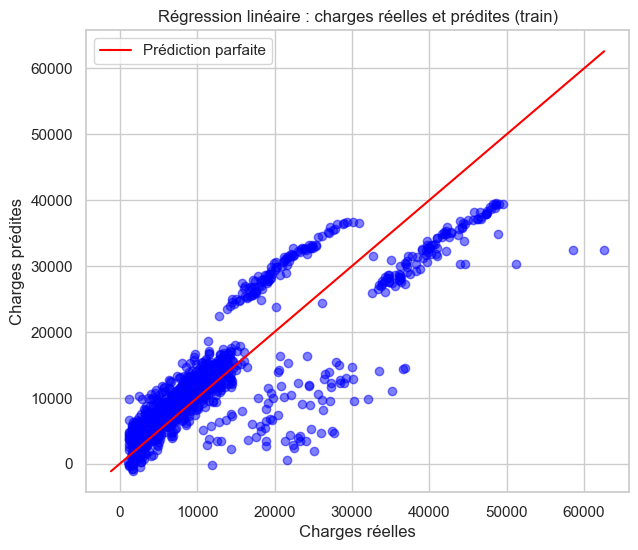

In [31]:
y_train_pred = modele_lineaire.predict(X_train)

plt.figure(figsize=(7, 6))
plt.scatter(y_train, y_train_pred, color="blue", alpha=0.5)

# Diagonale = prédiction parfaite (prédit = réel)
minimum = min(y_train.min(), y_train_pred.min())
maximum = max(y_train.max(), y_train_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], color="red", label="Prédiction parfaite")

plt.xlabel("Charges réelles")
plt.ylabel("Charges prédites")
plt.title("Régression linéaire : charges réelles et prédites (train)")
plt.legend()
plt.show()

**Lecture :** les points ne suivent pas la diagonale de façon homogène : ils forment des **groupes séparés**, et le modèle
se trompe nettement pour une partie des charges élevées. Un modèle purement additif ne capte pas toute la structure
des données ; les tests de l'étape 4 vont préciser pourquoi.

---
# **Étape 4 — Vérification des hypothèses de la régression linéaire**

Les résultats d'une régression linéaire (en particulier les **p-values** et **intervalles de confiance**)
ne sont fiables que si plusieurs hypothèses sont respectées :

| Hypothèse | Question posée | Outil utilisé |
|---|---|---|
| Linéarité | La relation est-elle bien linéaire ? | Graphique des résidus, test Rainbow |
| Homoscédasticité | La variance des erreurs est-elle constante ? | Test de Breusch-Pagan |
| Normalité des résidus | Les erreurs suivent-elles une loi normale ? | Q-Q plot, Shapiro-Wilk, Anderson-Darling, Kolmogorov-Smirnov |
| Absence de multicolinéarité | Les variables sont-elles redondantes ? | VIF |
| Pas de point trop influent | Une observation fausse-t-elle le modèle ? | Distance de Cook |

Les **résidus** sont les erreurs du modèle : `résidu = valeur réelle − valeur prédite`.

## **4.1 Linéarité et homoscédasticité**

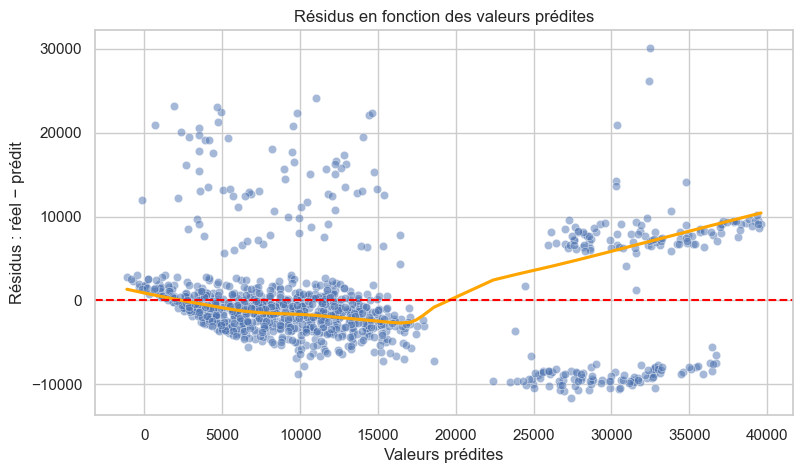

In [32]:
residus = y_train - y_train_pred

plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_train_pred, y=residus, alpha=0.5)
# Courbe LOWESS (orange) : tendance locale des résidus ; idéalement plate et proche de 0
sns.regplot(x=y_train_pred, y=residus, scatter=False, lowess=True, line_kws={"color": "orange"})
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valeurs prédites")
plt.ylabel("Résidus : réel − prédit")
plt.title("Résidus en fonction des valeurs prédites")
plt.show()

In [33]:
# Modèle équivalent avec statsmodels (nécessaire pour les tests statistiques)
X_train_const = sm.add_constant(X_train.astype(float), has_constant="add")
modele_sm = sm.OLS(y_train, X_train_const).fit()

# Test de Breusch-Pagan — H0 : la variance des résidus est constante (homoscédasticité)
_, p_breusch_pagan, _, _ = het_breuschpagan(modele_sm.resid, X_train_const)
print(f"P-value Breusch-Pagan : {p_breusch_pagan:.3g} ->",
      "hétéroscédasticité détectée" if p_breusch_pagan < 0.05 else "pas d'hétéroscédasticité détectée")

# Test Rainbow — H0 : la relation est linéaire
_, p_rainbow = linear_rainbow(modele_sm)
print(f"P-value Rainbow       : {p_rainbow:.3g} ->",
      "linéarité rejetée" if p_rainbow < 0.05 else "linéarité non rejetée")

P-value Breusch-Pagan : 3.32e-15 -> hétéroscédasticité détectée
P-value Rainbow       : 0.115 -> linéarité non rejetée


In [34]:
# Les groupes de résidus s'expliquent-ils par le tabac et l'obésité (IMC ≥ 30) ?
imc_reel = X_train["imc"] * ecarts_types["imc"] + moyennes["imc"]   # retour à l'IMC en kg/m²
groupes = pd.DataFrame({
    "fumeur": np.where(X_train["fumeur_Oui"] == 1, "Oui", "Non"),
    "obesite": np.where(imc_reel >= 30, "IMC ≥ 30", "IMC < 30"),
    "charges": y_train,
    "residu": residus,
})
groupes.groupby(["fumeur", "obesite"])[["charges", "residu"]].mean().round(0)

charges  residu
fumeur obesite                  
Non    IMC < 30   7934.0  1414.0
       IMC ≥ 30   9016.0 -1297.0
Oui    IMC < 30  21218.0 -8332.0
       IMC ≥ 30  41054.0  8332.0

**Interprétation :**

- **Homoscédasticité rejetée** (Breusch-Pagan, p ≈ 3e-15) : l'erreur du modèle n'a pas la même ampleur pour tous les assurés.
- **Linéarité non rejetée** par le test Rainbow (p ≈ 0,11). Attention : cela ne **prouve** pas la linéarité,
  le test ne la rejette simplement pas.
- Le tableau montre pourtant une **erreur structurée** : le modèle **sous-estime de 8 300 dollars** en moyenne
  les fumeurs obèses et **surestime d'autant** les fumeurs non obèses.

C'est exactement l'interaction **tabac × IMC** observée en 1.7, que le modèle linéaire simple ne peut pas représenter.
Comme on garde uniquement les variables fournies par l'entreprise, ce sont des modèles capables d'apprendre les interactions
**seuls** (régression polynomiale en 5.2, modèles à base d'arbres à l'étape 6) qui devront la capter.

## **4.2 Normalité des résidus : graphique Q-Q et tests**

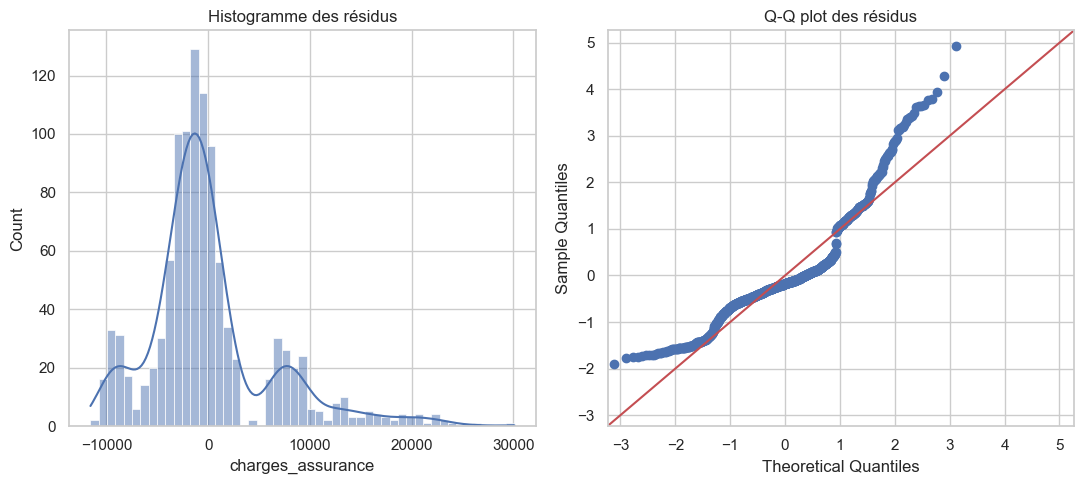

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
sns.histplot(x=residus, kde=True, ax=ax[0])
ax[0].set_title("Histogramme des résidus")

# Q-Q plot : si les résidus sont normaux, les points suivent la droite rouge
sm.qqplot(residus, line="45", fit=True, ax=ax[1])
ax[1].set_title("Q-Q plot des résidus")

plt.tight_layout()
plt.show()

In [36]:
# Trois tests de normalité — H0 : les résidus suivent une loi normale
test_shapiro = stats.shapiro(residus)
stat_anderson, p_anderson = normal_ad(residus.values)   # Anderson-Darling avec p-value
# Kolmogorov-Smirnov compare à une loi N(0, 1) : il faut d'abord standardiser les résidus
residus_standardises = (residus - residus.mean()) / residus.std()
test_ks = stats.kstest(residus_standardises, "norm")

normalite = pd.DataFrame({
    "Test": ["Shapiro-Wilk", "Anderson-Darling", "Kolmogorov-Smirnov"],
    "Statistique": [test_shapiro.statistic, stat_anderson, test_ks.statistic],
    "P-value": [test_shapiro.pvalue, p_anderson, test_ks.pvalue],
})
normalite["Normalité rejetée (5 %)"] = normalite["P-value"] < 0.05
normalite

,Test,Statistique,P-value,Normalité rejetée (5 %)
0,Shapiro-Wilk,0.886597,2.838705e-27,True
1,Anderson-Darling,41.847154,0.000000e+00,True
2,Kolmogorov-Smirnov,0.178992,1.956390e-30,True


**Interprétation :** les trois tests rejettent la normalité (p-values quasi nulles), ce que confirme le Q-Q plot
(les points s'écartent fortement de la droite aux extrémités).

Ce que cela change :

- **Pour prédire** : peu ou pas d'effet, un modèle peut bien prédire avec des résidus non normaux.
- **Pour interpréter** (p-values, intervalles de confiance des coefficients) : les résultats deviennent moins fiables.

## **4.3 Multicolinéarité : facteur d'inflation de la variance (VIF)**

Le VIF mesure à quel point une variable est expliquée par les autres. Règle usuelle : VIF > 5 (ou 10) = problème.

In [37]:
# VIF de chaque variable (on saute la colonne 0, qui est la constante)
vif = pd.DataFrame({
    "Variable": X_train.columns,
    "VIF": [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
})
vif.sort_values("VIF", ascending=False).round(3)

,Variable,VIF
5,region_Sud-Est,1.678
6,region_Sud-Ouest,1.555
4,region_Nord-Ouest,1.542
1,imc,1.111
0,age,1.021
3,fumeur_Oui,1.018
2,sexe_Homme,1.011


**Interprétation :** tous les VIF sont inférieurs à 1,7 : **aucune multicolinéarité**. Chaque coefficient mesure bien
l'effet propre de sa variable.

## **4.4 Points influents : distance de Cook**

La distance de Cook mesure à quel point les coefficients changent si on retire une observation. Seuils usuels :

| Règle | Seuil | Ici (n = 1 069, k = 7 variables) |
|---|---|---|
| 4/n (la plus répandue) | 4 / 1 069 | ≈ 0,0037 |
| 4/(n − k − 1) | 4 / (1 069 − 7 − 1) | ≈ 0,0038 |
| 1 (règle historique de Cook) | 1 | un point au-dessus est très suspect |

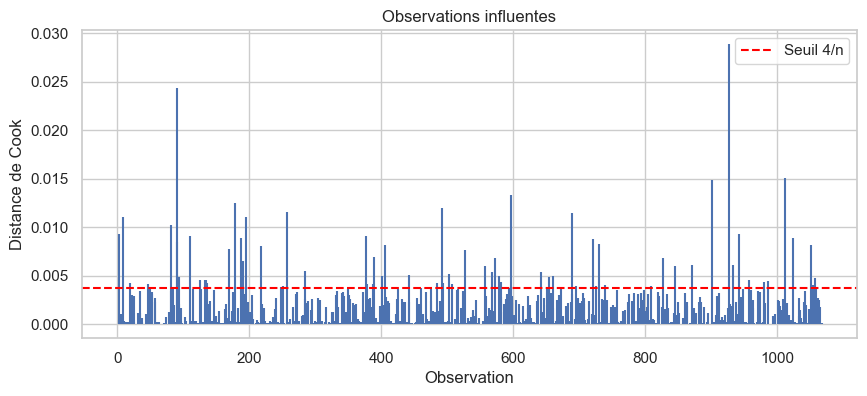

Observations au-dessus du seuil : 70 (6.5% du train)
Distance de Cook maximale       : 0.0289


,Part de fumeurs,Charges moyennes
Points influents,0.357,28263.709
Tout le train,0.200,13030.203


In [38]:
cook = modele_sm.get_influence().cooks_distance[0]
seuil_cook = 4 / len(cook)

plt.figure(figsize=(10, 4))
plt.stem(cook, markerfmt=" ", basefmt=" ")
plt.axhline(seuil_cook, color="red", linestyle="--", label="Seuil 4/n")
plt.xlabel("Observation")
plt.ylabel("Distance de Cook")
plt.title("Observations influentes")
plt.legend()
plt.show()

influents = X_train.index[cook > seuil_cook]
print(f"Observations au-dessus du seuil : {len(influents)} ({len(influents) / len(cook):.1%} du train)")
print(f"Distance de Cook maximale       : {cook.max():.4f}")

# Profil des observations influentes comparé à l'ensemble du train
profil = pd.DataFrame({
    "Part de fumeurs": [X_train.loc[influents, "fumeur_Oui"].mean(), X_train["fumeur_Oui"].mean()],
    "Charges moyennes": [y_train.loc[influents].mean(), y_train.mean()],
}, index=["Points influents", "Tout le train"])
profil.round(3)

In [39]:
# Analyse de sensibilité : que se passe-t-il si on retire ces points ?
# Le modèle d'origine n'est pas modifié ; on entraîne une copie sans les points influents.
modele_sans = LinearRegression().fit(X_train.drop(index=influents), y_train.drop(index=influents))

# Évaluation sur le MÊME jeu de test, qui n'est pas touché
for nom, m in [("Avec tous les points", modele_lineaire), ("Sans points influents", modele_sans)]:
    pred = m.predict(X_test)
    print(f"{nom:22s} | R² test : {r2_score(y_test, pred):.3f} | "
          f"RMSE test : {np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

Avec tous les points   | R² test : 0.807 | RMSE test : 5,952
Sans points influents  | R² test : 0.799 | RMSE test : 6,079


**Décision :** la distance de Cook maximale (≈ 0,03) est très loin du seuil critique de 1. Les points au-dessus du seuil 4/n
sont surtout des assurés aux frais élevés, avec davantage de fumeurs : ce sont des profils réels, pas des erreurs.
Leur retrait **n'améliore pas** le test (RMSE plus élevé) : **ces observations sont conservées**.

## **4.5 Inférence avec erreurs standards robustes (HC3)**

L'hétéroscédasticité rend les erreurs standards classiques fausses (donc aussi les p-values).
Les **erreurs robustes HC3** corrigent ce problème sans changer les coefficients.

In [40]:
modele_robuste = sm.OLS(y_train, X_train_const).fit(cov_type="HC3")
modele_robuste.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      charges_assurance   R-squared:                       0.727
Model:                            OLS   Adj. R-squared:                  0.725
Method:                 Least Squares   F-statistic:                     243.7
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          8.19e-216
Time:                        00:49:42   Log-Likelihood:                -10837.
No. Observations:                1069   AIC:                         2.169e+04
Df Residuals:                    1061   BIC:                         2.173e+04
Df Model:                           7                                         
Covariance Type:                  HC3                                         
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              8945.2521    455.527     19.637      0.000    8052.435    9838.069
age                3509.4296    194.859     18.010      0.000    3127.513    3891.346
imc                1930.2489    215.972      8.937      0.000    1506.951    2353.547
sexe_Homme         -103.2398    377.749     -0.273      0.785    -843.615     637.135
fumeur_Oui         2.311e+04    650.235     35.546      0.000    2.18e+04    2.44e+04
region_Nord-Ouest  -359.6027    542.999     -0.662      0.508   -1423.861     704.656
region_Sud-Est     -868.5569    587.327     -1.479      0.139   -2019.696     282.582
region_Sud-Ouest   -673.4196    522.998     -1.288      0.198   -1698.477     351.638
==============================================================================
Omnibus:                      265.018   Durbin-Watson:                   1.964
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              630.503
Skew:                           1.328   Prob(JB):                    1.22e-137
Kurtosis:                       5.665   Cond. No.                         5.72
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

**Bilan des hypothèses du modèle linéaire de référence :**

| Hypothèse | Résultat | Conséquence |
|---|---|---|
| Linéarité | Non rejetée par Rainbow, mais erreur structurée chez les fumeurs | Tester des modèles qui apprennent les interactions (5.2 et étape 6) |
| Homoscédasticité | Rejetée | Utiliser des erreurs robustes HC3 |
| Normalité des résidus | Rejetée par les trois tests | Interpréter les p-values avec prudence |
| Multicolinéarité | Absente (VIF < 1,7) | Aucune action |
| Points influents | Aucun point problématique | Observations conservées |

Avec les erreurs robustes, **`age`, `imc` et `fumeur_Oui` sont significatifs** (p < 0,05), contrairement au sexe et aux régions.

---
# **Étape 5 — Autres modèles linéaires**

On teste des variantes qui répondent chacune à un problème identifié à l'étape 4 : valeurs extrêmes (Huber),
interactions non prises en compte (polynomial) et cible positive et asymétrique (GLM Gamma).

## **5.1 Régression robuste : Huber**

La perte de Huber pénalise les grosses erreurs moins fortement que les moindres carrés :
le modèle est **moins sensible aux valeurs extrêmes** des charges.

In [41]:
modele_huber = HuberRegressor(epsilon=1.35, alpha=1e-4, max_iter=2000)
modele_huber.fit(X_train, y_train)

# Coefficients (avec la constante)
display(pd.DataFrame({
    "Variable": ["constante"] + list(X_train.columns),
    "Coefficient": [modele_huber.intercept_] + list(modele_huber.coef_),
}).round(1))

resultats_huber = calculer_metriques("Régression robuste (Huber)", modele_huber,
                                     X_train, y_train, X_test, y_test)

,Variable,Coefficient
0,constante,7687.0
1,age,3714.5
2,imc,334.3
3,sexe_Homme,-399.8
4,fumeur_Oui,27736.8
5,region_Nord-Ouest,-310.7
6,region_Sud-Est,-720.1
7,region_Sud-Ouest,-613.8


Régression robuste (Huber)


,Train,Test
R²,0.682,0.793
MSE,"43,543,262.163","38,123,899.632"
RMSE,"6,598.732","6,174.455"
MAE,"3,600.042","3,387.031"


**Lecture :** Huber réduit la MAE (erreur typique plus faible) mais augmente le RMSE et baisse le R² :
en ignorant en partie les grosses charges, il se trompe davantage sur les assurés les plus coûteux.
Ici, ces grosses charges sont réelles et importantes à prédire : Huber n'est pas adapté.

## **5.2 Régression polynomiale (degré 2)**

On ajoute automatiquement les carrés et tous les produits de variables deux à deux.
Le modèle peut ainsi capter des courbures et des interactions, sans savoir à l'avance lesquelles sont utiles.

In [42]:
modele_poly = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),   # carrés et produits croisés
    ("linreg", LinearRegression()),
])
modele_poly.fit(X_train, y_train)
print("Nombre de variables après expansion :", modele_poly.named_steps["poly"].n_output_features_)

resultats_poly = calculer_metriques("Polynomial (degré 2)", modele_poly,
                                    X_train, y_train, X_test, y_test)

Nombre de variables après expansion : 35
Polynomial (degré 2)


,Train,Test
R²,0.828,0.881
MSE,"23,581,299.012","21,776,294.441"
RMSE,"4,856.058","4,666.508"
MAE,"2,953.960","2,862.409"


**Lecture :** le passage de 7 à 35 variables améliore nettement les résultats : les interactions comptent.
Mais beaucoup de ces 35 variables sont inutiles (produits de deux régions toujours nuls, carrés de variables 0/1),
ce qui rend le modèle difficile à interpréter.

## **5.3 Modèle linéaire généralisé : régression Gamma (lien log)**

La loi Gamma convient aux cibles **strictement positives et asymétriques**, comme les frais médicaux (étape 1.5).
Avec le lien log, les effets deviennent **multiplicatifs** (en %).

In [43]:
# La loi Gamma n'accepte que des valeurs strictement positives
if (y_train > 0).all():
    modele_gamma = GammaRegressor(alpha=1e-4, max_iter=2000)
    modele_gamma.fit(X_train, y_train)

    resultats_gamma = calculer_metriques("GLM Gamma", modele_gamma, X_train, y_train, X_test, y_test)
    print("Déviance Gamma moyenne (test) :",
          round(mean_gamma_deviance(y_test, modele_gamma.predict(X_test)), 3))

    # Effet multiplicatif : exp(coefficient) − 1, ramené à +1 an ou +1 point d'IMC
    coef_reels = [coef / ecarts_types[var] if var in ecarts_types else coef
                  for var, coef in zip(X_train.columns, modele_gamma.coef_)]
    effets = pd.DataFrame({
        "Variable": X_train.columns,
        "Effet en % par unité réelle": (np.exp(coef_reels) - 1) * 100,
    }).sort_values("Effet en % par unité réelle", key=abs, ascending=False)
    display(effets.round(2))
else:
    print("La cible contient des valeurs ≤ 0 : GLM Gamma impossible (utiliser TweedieRegressor)")

GLM Gamma


,Train,Test
R²,0.597,0.736
MSE,"55,244,471.481","48,580,257.038"
RMSE,"7,432.662","6,969.954"
MAE,"4,373.111","4,027.712"


Déviance Gamma moyenne (test) : 0.21


,Variable,Effet en % par unité réelle
3,fumeur_Oui,330.94
6,region_Sud-Ouest,-11.24
5,region_Sud-Est,-10.70
2,sexe_Homme,-5.83
0,age,2.78
4,region_Nord-Ouest,-2.33
1,imc,1.39


---
# **Étape 6 — Modèles non linéaires**

Ces modèles apprennent **automatiquement** les interactions et les effets non linéaires, sans qu'on les précise.
Ils utilisent les mêmes 7 variables que la régression linéaire, toutes issues du jeu de données de l'entreprise.

## **6.1 Arbre de décision**

L'arbre découpe les assurés en groupes par une suite de questions (« fumeur ? », « IMC ≥ 30 ? »…)
et prédit la moyenne des charges de chaque groupe. `max_depth` et `min_samples_leaf` limitent sa taille pour éviter le surapprentissage.

In [44]:
modele_arbre = DecisionTreeRegressor(max_depth=5, min_samples_leaf=15, random_state=GRAINE)
modele_arbre.fit(X_train, y_train)

resultats_arbre = calculer_metriques("Arbre de décision", modele_arbre, X_train, y_train, X_test, y_test)

Arbre de décision


,Train,Test
R²,0.858,0.898
MSE,"19,479,903.645","18,694,348.302"
RMSE,"4,413.604","4,323.696"
MAE,"2,545.935","2,573.611"


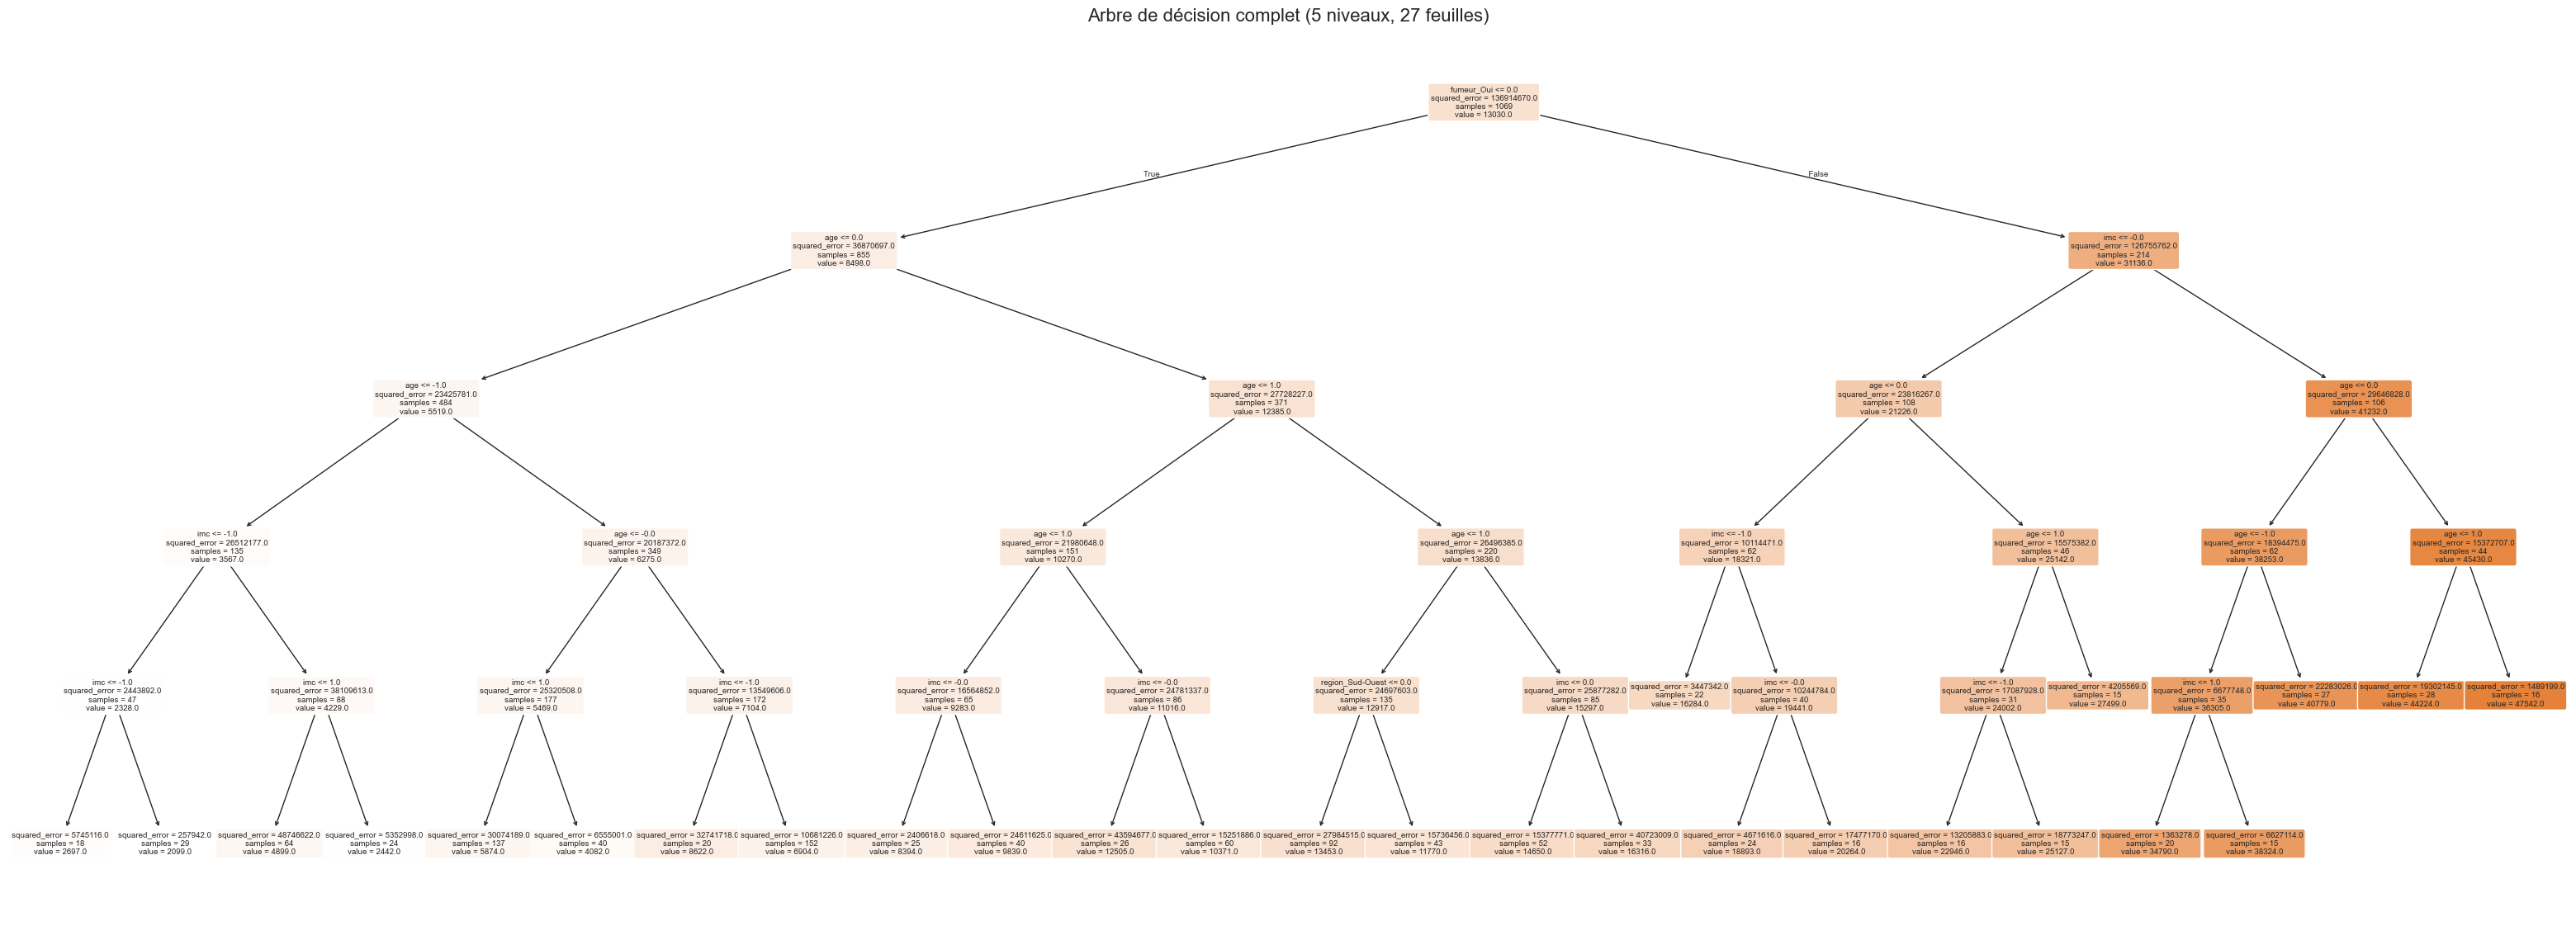

In [45]:
from sklearn.tree import plot_tree

# Visualiser l'arbre complet (5 niveaux, car max_depth=5 à l'entraînement)
plt.figure(figsize=(40, 14))   # figure large : jusqu'à 32 feuilles côte à côte
plot_tree(modele_arbre,
          feature_names=list(X_train.columns),
          filled=True,      # couleur selon la valeur prédite (plus foncé = charges plus élevées)
          rounded=True,
          fontsize=7,
          precision=0)      # valeurs arrondies à l'unité
plt.title(f"Arbre de décision complet ({modele_arbre.get_depth()} niveaux, "
          f"{modele_arbre.get_n_leaves()} feuilles)", fontsize=16)
plt.show()

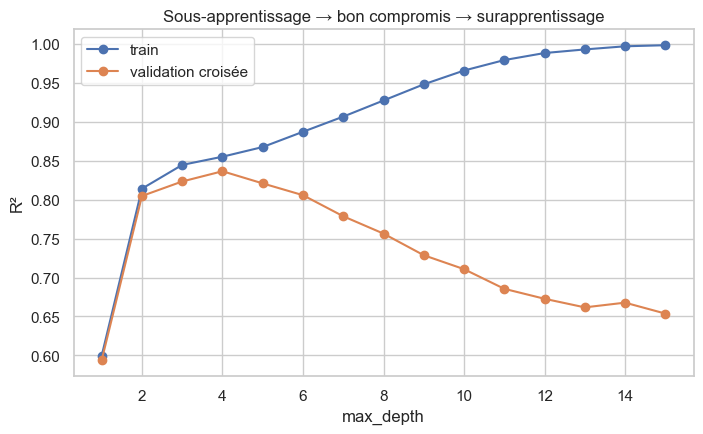

Profondeur optimale (validation) : 4


In [46]:
from sklearn.model_selection import validation_curve

profondeurs = range(1, 16)
score_train, score_val = validation_curve(
    DecisionTreeRegressor(random_state=42), X_train, y_train,
    param_name="max_depth", param_range=profondeurs, cv=5, scoring="r2"
)

plt.figure(figsize=(8, 4.5))
plt.plot(profondeurs, score_train.mean(axis=1), "o-", label="train")
plt.plot(profondeurs, score_val.mean(axis=1), "o-", label="validation croisée")
plt.xlabel("max_depth")
plt.ylabel("R²")
plt.title("Sous-apprentissage → bon compromis → surapprentissage")
plt.legend()
plt.show()
print("Profondeur optimale (validation) :", list(profondeurs)[int(score_val.mean(axis=1).argmax())])

## **6.2 Forêt aléatoire (Random Forest)**

Moyenne de 300 arbres, chacun entraîné sur un échantillon différent des données : plus stable qu'un arbre seul.

In [47]:
modele_rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.6,
                                  n_jobs=-1, random_state=GRAINE)
modele_rf.fit(X_train, y_train)

resultats_rf = calculer_metriques("Random Forest", modele_rf, X_train, y_train, X_test, y_test)

Random Forest


,Train,Test
R²,0.910,0.894
MSE,"12,364,099.909","19,443,082.653"
RMSE,"3,516.262","4,409.431"
MAE,"1,966.691","2,512.903"


## **6.3 Gradient Boosting avec réglage des hyperparamètres**

Le Gradient Boosting construit des petits arbres **l'un après l'autre**, chacun corrigeant les erreurs des précédents.
Ses hyperparamètres principaux (nombre d'arbres, taux d'apprentissage, profondeur) sont choisis par **recherche sur grille**
(`GridSearchCV`) en validation croisée à 5 plis, **sur le train uniquement**.

Les mêmes 5 plis (`cv`) seront réutilisés pour comparer tous les modèles à l'étape 7.

In [48]:
# Découpage en 5 plis, mélangé et reproductible, commun à toute la suite
cv = KFold(n_splits=5, shuffle=True, random_state=GRAINE)

grille = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3],
}
recherche = GridSearchCV(GradientBoostingRegressor(subsample=0.8, random_state=GRAINE),
                         grille, cv=cv, scoring="r2", n_jobs=-1)
recherche.fit(X_train, y_train)

print("Meilleurs hyperparamètres :", recherche.best_params_)
print(f"R² CV du meilleur réglage : {recherche.best_score_:.3f}")

# Le meilleur modèle est automatiquement réentraîné sur tout le train
modele_gb = recherche.best_estimator_
resultats_gb = calculer_metriques("Gradient Boosting (réglé)", modele_gb, X_train, y_train, X_test, y_test)

Meilleurs hyperparamètres : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}
R² CV du meilleur réglage : 0.838
Gradient Boosting (réglé)


,Train,Test
R²,0.855,0.900
MSE,"19,810,135.880","18,394,236.550"
RMSE,"4,450.858","4,288.850"
MAE,"2,539.255","2,504.433"


## **6.4 XGBoost**

Implémentation optimisée du Gradient Boosting, avec régularisation (`reg_lambda`) pour limiter le surapprentissage.

In [49]:
modele_xgb = XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8,
                          colsample_bytree=0.8, reg_lambda=5, min_child_weight=5,
                          n_jobs=-1, random_state=GRAINE, verbosity=0)
modele_xgb.fit(X_train, y_train)

resultats_xgb = calculer_metriques("XGBoost", modele_xgb, X_train, y_train, X_test, y_test)

XGBoost


,Train,Test
R²,0.876,0.899
MSE,"16,996,225.513","18,516,584.454"
RMSE,"4,122.648","4,303.090"
MAE,"2,276.612","2,477.356"


## **6.5 LightGBM**

Autre implémentation rapide du boosting, qui fait croître les arbres feuille par feuille (`num_leaves`).

In [50]:
modele_lgbm = LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=8, min_child_samples=20,
                            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                            n_jobs=-1, random_state=GRAINE, verbose=-1)
modele_lgbm.fit(X_train, y_train)

resultats_lgbm = calculer_metriques("LightGBM", modele_lgbm, X_train, y_train, X_test, y_test)

LightGBM


,Train,Test
R²,0.881,0.899
MSE,"16,230,953.053","18,567,702.017"
RMSE,"4,028.766","4,309.026"
MAE,"2,249.126","2,491.408"


## **6.6 SVR (Support Vector Regression)**

Le SVR avec noyau RBF capte des relations non linéaires. Il est sensible à l'échelle :
la cible est donc aussi standardisée automatiquement (`TransformedTargetRegressor`), puis remise en dollars pour la prédiction.

In [51]:
modele_svr = TransformedTargetRegressor(
    regressor=SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"),
    transformer=StandardScaler(),
)
modele_svr.fit(X_train, y_train)

resultats_svr = calculer_metriques("SVR (noyau RBF)", modele_svr, X_train, y_train, X_test, y_test)

SVR (noyau RBF)


,Train,Test
R²,0.847,0.881
MSE,"20,908,196.642","21,809,965.626"
RMSE,"4,572.548","4,670.114"
MAE,"2,124.230","2,380.934"


## **6.7 k plus proches voisins (k-NN)**

Le k-NN prédit la moyenne des charges des 15 assurés les plus proches.
On utilise des poids uniformes : avec `weights="distance"`, chaque point d'entraînement serait son propre voisin,
ce qui gonflerait artificiellement le R² train.

In [52]:
modele_knn = KNeighborsRegressor(n_neighbors=15, weights="uniform")
modele_knn.fit(X_train, y_train)

resultats_knn = calculer_metriques("k-NN", modele_knn, X_train, y_train, X_test, y_test)

k-NN


,Train,Test
R²,0.723,0.631
MSE,"37,987,543.210","67,726,839.776"
RMSE,"6,163.404","8,229.632"
MAE,"3,730.923","4,748.171"


---
# **Étape 7 — Comparaison de tous les modèles**

## **7.1 Tableau comparatif**

**Critère de choix : le R² moyen en validation croisée (5 plis)**, calculé sur le train avec les mêmes plis pour tous les modèles.
Il est plus fiable qu'un seul score sur le test, qui dépend du découpage (voir 3.3).

Le **surapprentissage** se lit avec l'écart *R² train − R² CV* : un grand écart signifie que le modèle
a « appris par cœur » le train et généralise moins bien.

In [53]:
# Chaque modèle est associé aux données qu'il utilise
modeles = {
    "Régression linéaire": (modele_lineaire, X_train, X_test),
    "Huber": (modele_huber, X_train, X_test),
    "Polynomial (degré 2)": (modele_poly, X_train, X_test),
    "Arbre de décision": (modele_arbre, X_train, X_test),
    "Random Forest": (modele_rf, X_train, X_test),
    "Gradient Boosting ": (modele_gb, X_train, X_test),
    "XGBoost": (modele_xgb, X_train, X_test),
    "LightGBM": (modele_lgbm, X_train, X_test),
    "SVR": (modele_svr, X_train, X_test),
    "k-NN": (modele_knn, X_train, X_test),
}
# Le GLM Gamma n'existe que si la cible est strictement positive (5.3)
if "modele_gamma" in globals():
    modeles["GLM Gamma"] = (modele_gamma, X_train, X_test)

lignes = []
for nom, (modele, Xtr, Xte) in modeles.items():
    pred_test = modele.predict(Xte)
    r2_train = r2_score(y_train, modele.predict(Xtr))

    # Validation croisée sur le train, avec une copie vierge du modèle (clone)
    scores_cv = cross_val_score(clone(modele), Xtr, y_train, cv=cv, scoring="r2")

    lignes.append({
        "Modèle": nom,
        "R² train": r2_train,
        "R² CV (moyenne)": scores_cv.mean(),
        "R² CV (écart-type)": scores_cv.std(),
        "R² test": r2_score(y_test, pred_test),
        "RMSE test": np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAE test": mean_absolute_error(y_test, pred_test),
        "Écart train − CV": r2_train - scores_cv.mean(),
    })

df_comparaison = (pd.DataFrame(lignes).set_index("Modèle")
                  .sort_values("R² CV (moyenne)", ascending=False))
df_comparaison.round(3)

,R² train,R² CV (moyenne),R² CV (écart-type),R² test,RMSE test,MAE test,Écart train − CV
Modèle,,,,,,,
Gradient Boosting,0.855,0.838,0.023,0.900,4288.850,2504.433,0.017
XGBoost,0.876,0.833,0.027,0.899,4303.090,2477.356,0.043
Random Forest,0.910,0.832,0.024,0.894,4409.431,2512.903,0.078
LightGBM,0.881,0.830,0.028,0.899,4309.026,2491.408,0.051
Arbre de décision,0.858,0.830,0.027,0.898,4323.696,2573.611,0.028
Polynomial (degré 2),0.828,0.816,0.021,0.881,4666.508,2862.409,0.012
SVR,0.847,0.815,0.024,0.881,4670.114,2380.934,0.032
Régression linéaire,0.727,0.720,0.029,0.807,5952.147,4175.911,0.007
Huber,0.682,0.660,0.057,0.793,6174.455,3387.031,0.022


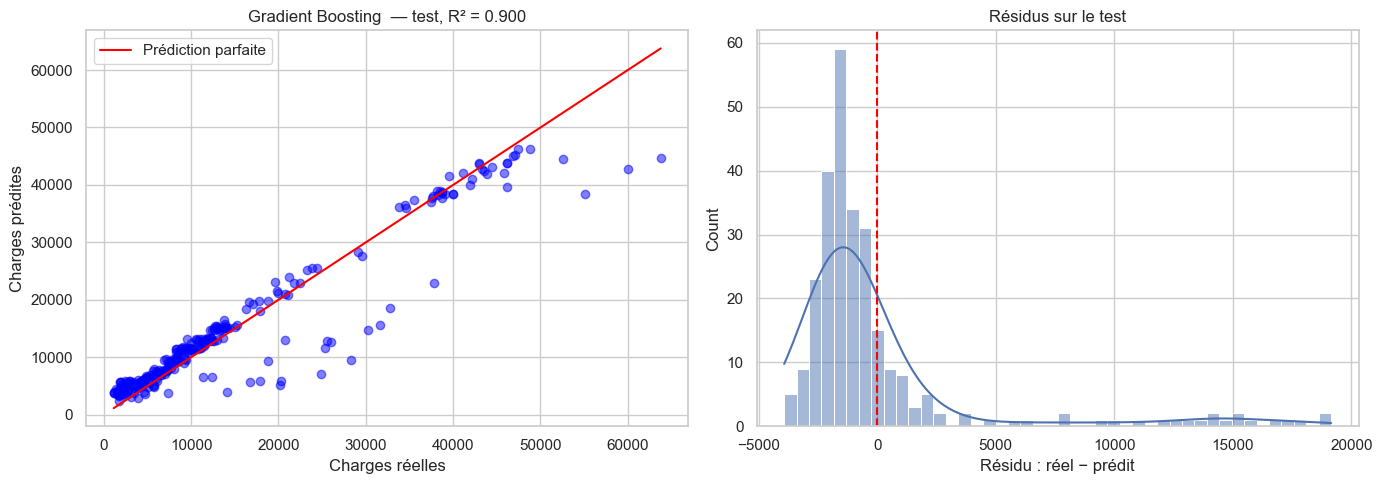

Meilleur modèle en validation croisée : Gradient Boosting 
Résidu moyen : 6 | Résidu médian : -1,316


In [54]:
# Le meilleur modèle selon la validation croisée (Gradient Boosting réglé)
meilleur = df_comparaison.index[0]

# Chaque entrée du dictionnaire contient : (modèle, X_train, X_test)
modele_meilleur, _, X_test_meilleur = modeles[meilleur]

y_test_pred_meilleur = modele_meilleur.predict(X_test_meilleur)
residus_test = y_test - y_test_pred_meilleur

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# 1. Valeurs réelles et prédites sur le test
axs[0].scatter(y_test, y_test_pred_meilleur, color="blue", alpha=0.5)
lim = [min(y_test.min(), y_test_pred_meilleur.min()),
       max(y_test.max(), y_test_pred_meilleur.max())]
axs[0].plot(lim, lim, color="red", label="Prédiction parfaite")
axs[0].set_xlabel("Charges réelles")
axs[0].set_ylabel("Charges prédites")
axs[0].set_title(f"{meilleur} — test, R² = {r2_score(y_test, y_test_pred_meilleur):.3f}")
axs[0].legend()

# 2. Distribution des erreurs (réel − prédit)
sns.histplot(residus_test, kde=True, ax=axs[1])
axs[1].axvline(0, color="red", linestyle="--")
axs[1].set_xlabel("Résidu : réel − prédit")
axs[1].set_title("Résidus sur le test")

plt.tight_layout()
plt.show()

print("Meilleur modèle en validation croisée :", meilleur)
print(f"Résidu moyen : {residus_test.mean():,.0f} | Résidu médian : {residus_test.median():,.0f}")

## **7.2 Comparaison graphique**

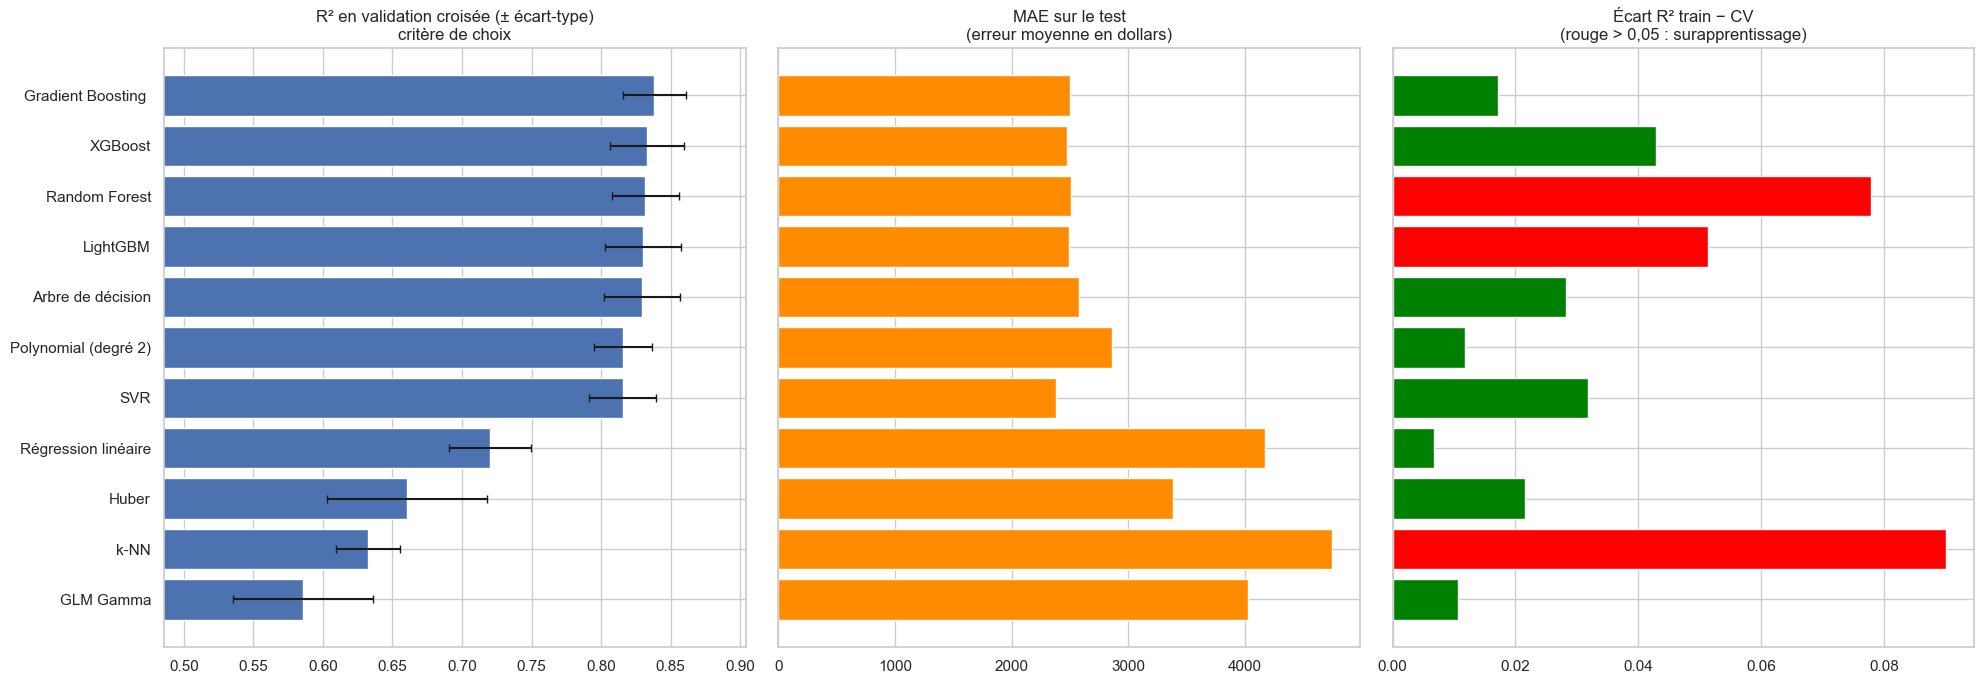

In [55]:
ordre = df_comparaison.index[::-1]   # meilleur modèle en haut

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)

# 1. R² en validation croisée (critère de choix), avec son écart-type
axes[0].barh(ordre, df_comparaison.loc[ordre, "R² CV (moyenne)"],
             xerr=df_comparaison.loc[ordre, "R² CV (écart-type)"], capsize=3)
axes[0].set_title("R² en validation croisée (± écart-type)\ncritère de choix")
axes[0].set_xlim(left=max(0, df_comparaison["R² CV (moyenne)"].min() - 0.1))

# 2. Erreur sur le test, en dollars
axes[1].barh(ordre, df_comparaison.loc[ordre, "MAE test"], color="darkorange")
axes[1].set_title("MAE sur le test\n(erreur moyenne en dollars)")

# 3. Surapprentissage
couleurs = ["red" if v > 0.05 else "green" for v in df_comparaison.loc[ordre, "Écart train − CV"]]
axes[2].barh(ordre, df_comparaison.loc[ordre, "Écart train − CV"], color=couleurs)
axes[2].set_title("Écart R² train − CV\n(rouge > 0,05 : surapprentissage)")

plt.tight_layout()
plt.show()

**Lecture du comparatif :**

- **Trois groupes de modèles se dégagent :**
  - **les meilleurs** (R² CV entre 0,83 et 0,84) : les modèles à base d'arbres (Gradient Boosting, XGBoost, Random Forest, LightGBM, arbre seul). Ils apprennent seuls l'interaction tabac × IMC ;
  - **les intermédiaires** (≈ 0,82) : le polynomial et le SVR, qui captent aussi les interactions, mais moins bien ;
  - **les plus faibles** (< 0,73) : la régression linéaire simple, Huber, k-NN et le GLM Gamma, qui ne représentent pas cette interaction.
- **Le Gradient Boosting réglé arrive en tête** (R² CV = 0,838 ± 0,023). XGBoost, Random Forest, LightGBM et l'arbre seul
  sont très proches (0,830 à 0,832) : les écarts sont plus petits que l'écart-type, ces modèles sont **à égalité statistique**.
- **Surapprentissage :** à performance égale, le Gradient Boosting réglé est le plus stable (écart train − CV de 0,017),
  alors que la Random Forest (0,078), LightGBM (0,051) et le k-NN (0,089) collent davantage au train.
- Par rapport à la régression linéaire (R² CV de 0,720), le Gradient Boosting gagne près de **12 points de R²** et divise
  l'erreur moyenne sur le test (MAE) par environ 1,7 : de 4 176 à 2 504 dollars.

---
# **Étape 8 — Modèle final et conclusion**

## **8.1 Évaluation du modèle retenu sur le test**

Modèle retenu : Gradient Boosting 
Hyperparamètres : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}


,R² train,R² CV (moyenne),R² CV (écart-type),R² test,RMSE test,MAE test,Écart train − CV
Modèle,,,,,,,
Gradient Boosting,0.855,0.838,0.023,0.9,4288.85,2504.433,0.017


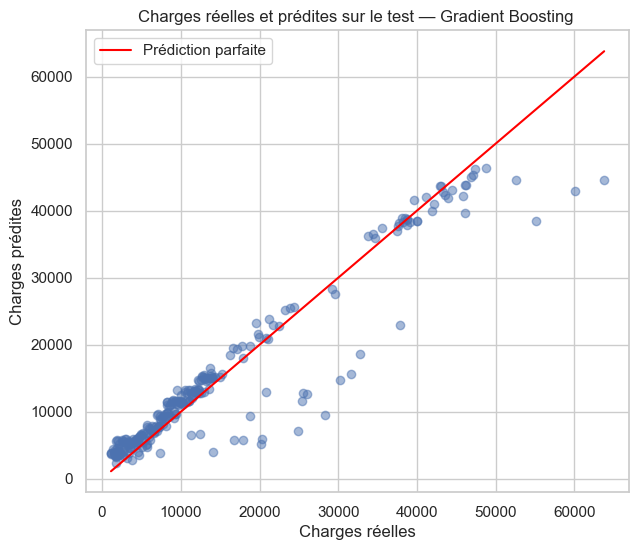

In [56]:
# Modèle final : Gradient Boosting réglé (6.3), meilleur R² en validation croisée
# On cherche la ligne du tableau dont le nom contient "Gradient Boosting"
nom_final = next(nom for nom in df_comparaison.index if "Gradient Boosting" in nom)
modele_final = modele_gb
print("Modèle retenu :", nom_final)
print("Hyperparamètres :", recherche.best_params_)
display(df_comparaison.loc[[nom_final]].round(3))

# Prédictions sur le jeu de test (jamais utilisé pour faire un choix)
pred_final = modele_final.predict(X_test)

# Bornes de la diagonale de prédiction parfaite
minimum = min(y_test.min(), pred_final.min())
maximum = max(y_test.max(), pred_final.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_final, alpha=0.5)
plt.plot([minimum, maximum], [minimum, maximum], color="red", label="Prédiction parfaite")
plt.xlabel("Charges réelles")
plt.ylabel("Charges prédites")
plt.title(f"Charges réelles et prédites sur le test — {nom_final}")
plt.legend()
plt.show()

## **8.2 Exemple d'utilisation : prédire les frais d'un nouvel assuré**

In [57]:
def predire_charges(age, imc, sexe, fumeur, region):
    """Prédit les frais médicaux d'un assuré avec le Gradient Boosting réglé, à partir de données brutes."""
    # enfants = 0 : valeur provisoire, car le scaler a été appris sur age, imc et enfants.
    # La variable est retirée juste après : elle n'influence pas la prédiction.
    brut = pd.DataFrame([{"age": age, "imc": imc, "enfants": 0,
                          "sexe": sexe, "fumeur": fumeur, "region": region}])

    # Mêmes transformations que pour l'entraînement :
    # 1. encodage One-Hot avec l'encodeur déjà appris (2.1)
    encode = pd.DataFrame(encodeur.transform(brut[colonnes_cat]),
                          columns=encodeur.get_feature_names_out(colonnes_cat))
    x = pd.concat([brut[colonnes_num], encode], axis=1)

    # 2. standardisation avec la moyenne et l'écart-type du train (2.4)
    x[colonnes_num] = scaler.transform(x[colonnes_num])

    # 3. mêmes colonnes, dans le même ordre que pour l'entraînement (enfants retirée en 2.6)
    x = x[X_train.columns]

    return modele_gb.predict(x)[0]


# Même homme de 45 ans du Sud-Est : on fait varier le tabac et l'IMC (25 = normal, 35 = obèse)
exemples = [
    (45, 25, "Homme", "Non", "Sud-Est"),
    (45, 25, "Homme", "Oui", "Sud-Est"),
    (45, 35, "Homme", "Non", "Sud-Est"),
    (45, 35, "Homme", "Oui", "Sud-Est"),
]
pd.DataFrame(
    [{"Âge": a, "IMC": i, "Sexe": s, "Fumeur": f, "Région": r,
      "Charges prédites ($)": round(predire_charges(a, i, s, f, r))} for a, i, s, f, r in exemples]
)

,Âge,IMC,Sexe,Fumeur,Région,Charges prédites ($)
0,45,25,Homme,Non,Sud-Est,9200
1,45,25,Homme,Oui,Sud-Est,24478
2,45,35,Homme,Non,Sud-Est,9502
3,45,35,Homme,Oui,Sud-Est,42299


In [ ]:
joblib.dump(modele_gb, "modele_gb.pkl")

['modele_gb.pkl']

: 

## **8.3 Conclusion**

### Modèle retenu : Gradient Boosting avec hyperparamètres réglés

| Indicateur | Valeur |
|---|---|
| R² en validation croisée (critère de choix) | **0,838 ± 0,023** |
| R² sur le test | 0,900 |
| RMSE sur le test | ≈ 4 290 dollars |
| MAE sur le test | ≈ 2 500 dollars |
| Écart R² train − CV (surapprentissage) | 0,017 |

Réglages retenus par la recherche sur grille (6.3) : 200 arbres, taux d'apprentissage 0,03, profondeur 2.

**Pourquoi ce modèle ?** Il a le meilleur R² en validation croisée et le plus faible surapprentissage parmi les modèles
les plus performants. Il n'utilise **que les variables fournies par l'entreprise**, sans variable créée à la main, et
capte **seul** l'interaction entre le tabac et l'IMC que la régression linéaire ne pouvait pas représenter.
XGBoost, Random Forest et LightGBM font presque aussi bien : à performance égale, on choisit le plus stable.

### Principaux enseignements

1. **Le tabagisme est le facteur n°1** : la charge médiane d'un fumeur est plus de 4 fois celle d'un non-fumeur (1.5),
   et c'est le coefficient le plus élevé de la régression linéaire (≈ +23 100 dollars, 3.2).
2. **L'IMC compte surtout chez les fumeurs** (r ≈ 0,81 chez les fumeurs contre 0,08 chez les non-fumeurs, 1.7).
   Exemple (8.2) : pour un homme fumeur de 45 ans, passer d'un IMC de 25 à 35 fait passer les frais prédits
   d'environ 24 500 à 42 300 dollars ; pour un non-fumeur, la différence n'est que d'environ 300 dollars.
3. **L'âge** fait augmenter les frais régulièrement (≈ +250 dollars par an dans la régression linéaire).
4. **Le sexe, la région et le nombre d'enfants** ont peu ou pas d'effet (non significatifs en 4.5, `enfants` écartée en 2.5).

### Démarche à retenir

- La corrélation globale de Pearson aurait pu faire sous-estimer l'IMC : **l'analyse par sous-groupe** (1.7)
  et **l'analyse des résidus** (4.1) ont révélé l'interaction tabac × IMC, qui explique pourquoi les modèles à base
  d'arbres dépassent nettement la régression linéaire.
- Tous les choix (variables, hyperparamètres, modèle) ont été faits **sans utiliser le jeu de test**.

### Limites et pistes d'amélioration

- **R² test optimiste :** le test est plus dispersé que le train (3.3) ; le R² CV (0,838) est l'estimation la plus prudente.
- **Interprétabilité :** le Gradient Boosting n'a pas de coefficients ; il est moins facile à justifier auprès d'un client
  qu'une régression linéaire.
- **Hypothèses :** les tests de l'étape 4 concernent la régression linéaire de référence, pas le modèle retenu.
- **Standardisation avant la validation croisée :** le scaler est appris sur tout le train avant la validation croisée.
  L'effet est négligeable ici, mais un `Pipeline` scikit-learn l'éviterait complètement.
- **Réglage des hyperparamètres :** seul le Gradient Boosting a été optimisé ; XGBoost et LightGBM pourraient gagner un peu avec un réglage.
- **Données :** 1 337 observations, une seule source, pas de variables médicales (antécédents, maladies chroniques) ;
  le modèle n'a pas été validé sur des données externes.

**Pistes :** intégrer le prétraitement dans des `Pipeline`, régler aussi XGBoost et LightGBM, mesurer l'importance
des variables (permutation ou SHAP) pour expliquer le modèle, et le déployer dans une petite application Streamlit.